In [10]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

In [11]:
def catenary(x, a, c, x0):
    """Modello di catenaria."""
    return c + a * np.cosh((x - x0) / a)

In [12]:
# Come prima: usate il percorso al vostro file.
file_path = 'catenaria.txt'
x, y = np.loadtxt(file_path, unpack=True)
# Ricordate: il riferimento delle immagini, tipicamente, è in alto a sinistra,
# per cui potreste aver bisogno di cambiare segno alla y.
y = -y
# Fate attenzione alle incertezze: il valore, qui, è completamente arbitrario.
sigma_y = 10.0

896.744721211153 9.976154621007627 -2484.6995696543495 9.881124609514579 2269.048687901831 6.273751792099564


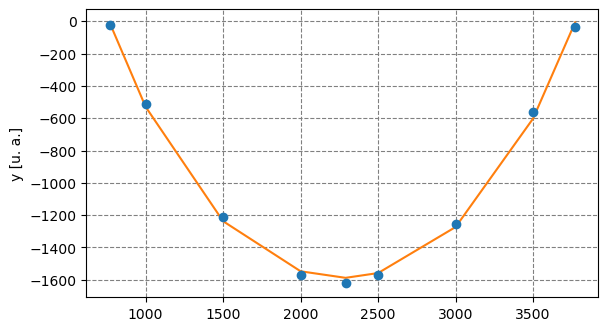

In [13]:
# Grafico principale.
fig = plt.figure('Fit e residui')
fig.add_axes((0.1, 0.3, 0.8, 0.6))
plt.errorbar(x, y, sigma_y, fmt='o')

# Fit. Notate che, per far convergere il fit, avrete bisogno di fornire una
# stima iniziale ragionevole dei parametri.
popt, pcov = curve_fit(catenary, x, y, p0=(1000.0, -3000.0, 2300.0))
a_hat, c_hat, x0_hat = popt
sigma_a, sigma_c, sigma_x0 = np.sqrt(pcov.diagonal())
print(a_hat, sigma_a, c_hat, sigma_c, x0_hat, sigma_x0)
plt.plot(x, catenary(x, a_hat, c_hat, x0_hat))
plt.grid(which='both', ls='dashed', color='gray')
plt.ylabel('y [u. a.]')

plt.show()

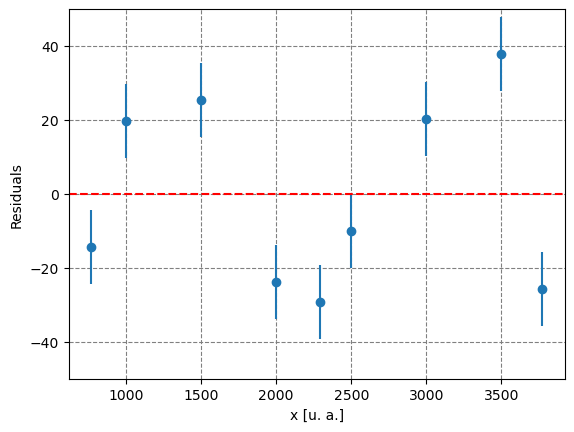

In [14]:
# Grafico dei residui.
fig.add_axes((0.1, 0.1, 0.8, 0.2))
res = y - catenary(x, a_hat, c_hat, x0_hat)
plt.errorbar(x, res, sigma_y, fmt='o')
plt.grid(which='both', ls='dashed', color='gray')
plt.xlabel('x [u. a.]')
plt.ylabel('Residuals')
plt.ylim(-50.0, 50.0)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual Line')

plt.show()

In [15]:
# Chi-squared test


chi = np.sum((res/sigma_y)**2) 

print(chi)

52.716448579528326
